<a href="https://colab.research.google.com/github/dineshmantena77/house_price_estimator/blob/main/House_Price_Estimator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mean Squared Error (MSE): 719032292.22
R-squared Score (R2): 0.8960


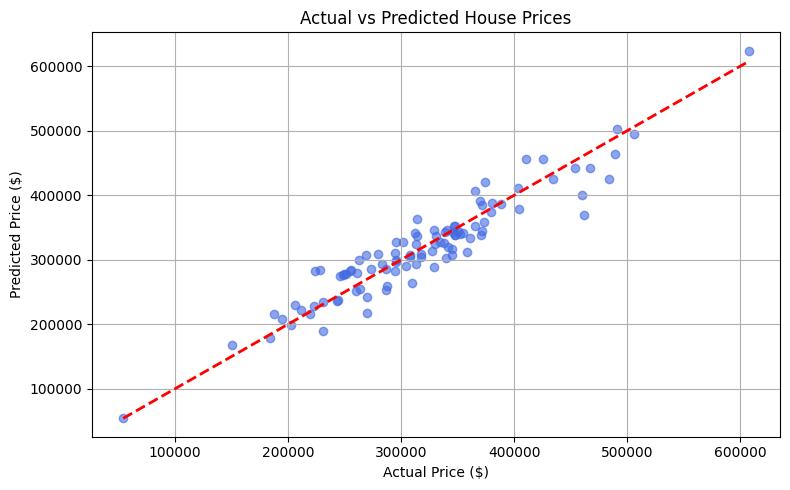

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Create a realistic dataset (Simulating raw tabular property data)
np.random.seed(42)
n_samples = 500

data = {
    'Area_SqFt': np.random.normal(2000, 500, n_samples),
    'Bedrooms': np.random.randint(1, 6, n_samples),
    'Age_Years': np.random.randint(0, 30, n_samples),
    'Furnishing': np.random.choice(['Furnished', 'Semi-Furnished', 'Unfurnished'], n_samples)
}
df = pd.DataFrame(data)

# Generate realistic target prices with some random noise
df['Price'] = (df['Area_SqFt'] * 150) + (df['Bedrooms'] * 15000) - (df['Age_Years'] * 2000) + np.random.normal(0, 25000, n_samples)

# Introduce a few missing values to demonstrate data cleaning
df.loc[0:10, 'Area_SqFt'] = np.nan

# 2. Data Cleaning & Preprocessing
# Handle missing entries by filling with the median
df['Area_SqFt'] = df['Area_SqFt'].fillna(df['Area_SqFt'].median())

# Encode categorical features (One-Hot Encoding for 'Furnishing')
df = pd.get_dummies(df, columns=['Furnishing'], drop_first=True)

# Separate features (X) and target (y)
X = df.drop('Price', axis=1)
y = df['Price']

# Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize numerical distributions
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Model Training (Linear Regression)
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# 4. Model Evaluation
y_pred = model.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared Score (R2): {r2:.4f}")

# 5. Visualization: Actual vs Predicted Prices
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6, color='royalblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.grid(True)
plt.tight_layout()
plt.savefig('price_predictions.png')
plt.show()